## Lab 2 - Task 1: CNN on mel-spectrograms (Keras)

- Build 80/20 split (song level; reuse the same one as Lab 1)
- Load the spectrograms (cropped, RGB)
- Explore CNN configurations using a validation split taken only from the 80%
- Retrain the best one on the full train set and evaluate once on the 20% test set

In [ ]:
%pip install tensorflow

In [1]:
import os, re, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
DATA_ROOT   = Path("data")
IMG_DIR     = DATA_ROOT / "images_original"
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
SEED = 42

def set_seed(s):
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)   # python + numpy + tensorflow
set_seed(SEED)
print('GPUs:', tf.config.list_physical_devices('GPU'))

GPUs: []


In [3]:
pat  = re.compile(r'^([a-z]+)(\d{5})\.png$')          # e.g. blues00000.png
rows = []
for gdir in sorted(p for p in IMG_DIR.iterdir() if p.is_dir()):
    for f in sorted(gdir.glob('*.png')):
        m = pat.match(f.name)
        if m:
            rows.append(dict(song=f'{m.group(1)}.{m.group(2)}', genre=m.group(1), path=str(f)))

songs = pd.DataFrame(rows)
GENRES = sorted(songs.genre.unique())                 # alphabetical = same as LabelEncoder in Lab 1
songs['label'] = songs.genre.map({g:i for i,g in enumerate(GENRES)})
print(len(songs), 'songs'); print(songs.genre.value_counts().to_string())

999 songs
genre
blues        100
classical    100
country      100
disco        100
hiphop       100
metal        100
pop          100
reggae       100
rock         100
jazz          99


(432, 288) RGBA


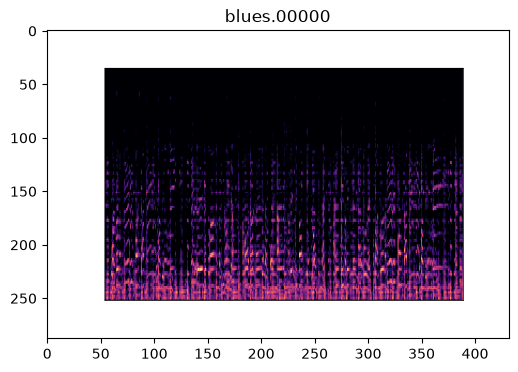

In [4]:
im = Image.open(songs.path[0]); print(im.size, im.mode)
plt.figure(figsize=(6,4)); plt.imshow(im); plt.title(songs.song[0]); plt.show()

We see that there are margins in the image (matplotlib figure with white frame and axes), so we have to crop them. The images are also RGBA, so we convert them to RGB.

The real spectrogram occupies approximately x in [55, 388] and y in [37, 251] pixels. The horizontal axis is time (30 s), the vertical axis is mel frequency (low frequencies at the bottom).

### Split 80/20 (song level, stratified by genre)

In [5]:
tr, te = train_test_split(songs.song, test_size=0.2, stratify=songs.genre, random_state=SEED)
split = dict(train=sorted(tr), test=sorted(te))   # can be exported later to unify with Lab 1

# inner validation split, taken ONLY from the training songs (for model selection)
tr_songs = songs[songs.song.isin(split['train'])]
sub_tr, sub_va = train_test_split(tr_songs.song, test_size=0.2, stratify=tr_songs.genre, random_state=SEED)

idx_of = lambda names: songs.index[songs.song.isin(set(names))].to_numpy()
IDX_TRAIN, IDX_TEST = idx_of(split['train']), idx_of(split['test'])
IDX_SUB_TR, IDX_VAL = idx_of(sub_tr), idx_of(sub_va)
print(len(IDX_TRAIN), len(IDX_TEST), '| inner:', len(IDX_SUB_TR), len(IDX_VAL))
assert not set(IDX_TRAIN) & set(IDX_TEST)

799 200 | inner: 639 160


### Crop, resize and load the spectrograms into memory (uint8, channels-last)

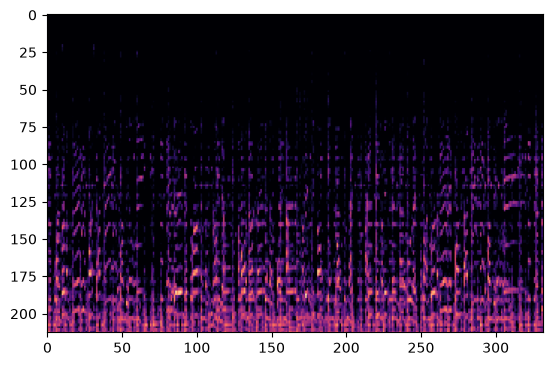

(999, 128, 192, 3) 73.654272 MB


In [6]:
IMG_H, IMG_W = 128, 192        # height (frequency) x width (time)
CROP = (55, 37, 387, 250)      # (left, top, right, bottom) in pixels of the original image

def load_img(p):
    im = Image.open(p).convert('RGB').crop(CROP)                      # RGBA -> RGB, remove margins
    return np.asarray(im.resize((IMG_W, IMG_H), Image.BILINEAR))      # H,W,3 uint8

# visual check: no white margin or black frame should remain
plt.imshow(Image.open(songs.path[0]).convert('RGB').crop(CROP)); plt.show()

X_all = np.stack([load_img(p) for p in songs.path])                   # N,H,W,3 uint8
y_all = songs.label.to_numpy()
print(X_all.shape, X_all.nbytes / 1e6, 'MB')

# normalisation stats from TRAIN only
_tr  = X_all[IDX_TRAIN].astype('float32') / 255.
MEAN = _tr.mean((0, 1, 2)); STD = _tr.std((0, 1, 2)); del _tr

### Data pipeline (tf.data) with SpecAugment-style masking

In [7]:
def spec_mask(x, y, fmask=16, tmask=24):
    f  = tf.random.uniform([], 0, fmask + 1, tf.int32); f0 = tf.random.uniform([], 0, IMG_H - f + 1, tf.int32)
    t  = tf.random.uniform([], 0, tmask + 1, tf.int32); t0 = tf.random.uniform([], 0, IMG_W - t + 1, tf.int32)
    rows, cols = tf.range(IMG_H), tf.range(IMG_W)
    row_m = (rows >= f0) & (rows < f0 + f)                 # frequency band
    col_m = (cols >= t0) & (cols < t0 + t)                 # time band
    mask  = row_m[:, None] | col_m[None, :]                # H,W
    return tf.where(mask[:, :, None], 0.0, x), y           # 0 = mean after normalisation

def make_ds(idx, augment=False, bs=32, shuffle=False):
    x = (X_all[idx].astype('float32') / 255. - MEAN) / STD
    ds = tf.data.Dataset.from_tensor_slices((x, y_all[idx]))
    if shuffle: ds = ds.shuffle(len(idx), seed=SEED)
    if augment: ds = ds.map(spec_mask, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)

## Model: configurable CNN

In [8]:
def SimpleCNN(filters=(16, 32, 64), kernel=(3, 3), dropout=0.3, n_classes=10, input_shape=None):
    input_shape = input_shape or (IMG_H, IMG_W, 3)
    inp = keras.Input(shape=input_shape)
    x = inp
    for f in filters:
        x = layers.Conv2D(f, kernel, padding='same')(x)    # kernel = (alto=frecuencia, ancho=tiempo)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(n_classes)(x))
# trainable parameters only
n_params = lambda m: int(sum(np.prod(tuple(w.shape)) for w in m.trainable_weights))
print(n_params(SimpleCNN()))

24458


In [ ]:
SIZE_CACHE = {(IMG_H, IMG_W): (X_all, MEAN, STD)}

def set_input_size(h, w):
    global X_all, MEAN, STD, IMG_H, IMG_W
    if (h, w) not in SIZE_CACHE:
        def _load(p): return np.asarray(Image.open(p).convert('RGB').crop(CROP).resize((w, h), Image.BILINEAR))
        X = np.stack([_load(p) for p in songs.path])
        t = X[IDX_TRAIN].astype('float32') / 255.
        SIZE_CACHE[(h, w)] = (X, t.mean((0, 1, 2)), t.std((0, 1, 2)))
    X_all, MEAN, STD = SIZE_CACHE[(h, w)]
    IMG_H, IMG_W = h, w

In [ ]:
RESULTS_CSV = RESULTS_DIR / 'task1_experiments.csv'

BASE = dict(filters=(32, 64, 128), kernel=(3, 3), dropout=0.3, augment=True, lr=1e-3, size=(128, 192))

EXPERIMENTS = {
    # --- profundidad / filtros ---
    '2conv_16-32':             dict(filters=(16, 32)),
    '3conv_16-32-64':          dict(filters=(16, 32, 64)),
    '3conv_32-64-128':         dict(filters=(32, 64, 128)),
    '4conv_16-32-64-128':      dict(filters=(16, 32, 64, 128)),
    '4conv_32-64-128-256':     dict(filters=(32, 64, 128, 256)),
    '5conv_32-64-128-256-256': dict(filters=(32, 64, 128, 256, 256)),
    # --- un factor cada vez sobre BASE ---
    'dropout_0.0':     dict(dropout=0.0),
    'dropout_0.5':     dict(dropout=0.5),
    'no_augment':      dict(augment=False),
    'lr_3e-4':         dict(lr=3e-4),
    'lr_3e-3':         dict(lr=3e-3),
    'kernel_5x5':      dict(kernel=(5, 5)),
    'kernel_7x3_freq': dict(kernel=(7, 3)),   # alto en frecuencia
    'kernel_3x7_time': dict(kernel=(3, 7)),   # ancho en tiempo
    'size_64x96':      dict(size=(64, 96)),
    'size_192x288':    dict(size=(192, 288)),
}

def fmt(cfg):
    return dict(filters='-'.join(map(str, cfg['filters'])), kernel='x'.join(map(str, cfg['kernel'])),
                dropout=cfg['dropout'], augment=cfg['augment'], lr=cfg['lr'],
                img_h=cfg['size'][0], img_w=cfg['size'][1])

done = set(pd.read_csv(RESULTS_CSV).name) if RESULTS_CSV.exists() else set()   # reanuda si se corta
runs = {}
for name, over in EXPERIMENTS.items():
    if name in done:
        print('skip (ya hecho):', name); continue
    cfg = {**BASE, **over}
    print('=====', name, fmt(cfg))
    set_input_size(*cfg['size'])
    keras.backend.clear_session()
    out = train_model(SimpleCNN(filters=cfg['filters'], kernel=cfg['kernel'], dropout=cfg['dropout']),
                      IDX_SUB_TR, IDX_VAL, lr=cfg['lr'], augment=cfg['augment'])
    runs[name] = out
    row = dict(name=name, **fmt(cfg), depth=len(cfg['filters']), params=out['params'],
               best_val_acc=out['best_val'], best_epoch=out['best_epoch'], train_time_s=out['train_time'])
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)   # guarda ya
    print({k: row[k] for k in ('best_val_acc', 'best_epoch', 'params', 'train_time_s')})

set_input_size(*BASE['size'])
res_df = pd.read_csv(RESULTS_CSV).sort_values('best_val_acc', ascending=False); res_df

In [ ]:
best = res_df.iloc[0]; print('best on validation:', best['name'])
BEST_CFG = dict(filters=tuple(map(int, best.filters.split('-'))), kernel=tuple(map(int, best.kernel.split('x'))),
                dropout=float(best.dropout), augment=bool(best.augment), lr=float(best.lr), size=(int(best.img_h), int(best.img_w)))
BEST_EPOCH, best_name = int(best.best_epoch), best['name']
set_input_size(*BEST_CFG['size'])
keras.backend.clear_session()
final = train_model(SimpleCNN(filters=BEST_CFG['filters'], kernel=BEST_CFG['kernel'], dropout=BEST_CFG['dropout']),
                    IDX_TRAIN, None, epochs=BEST_EPOCH, lr=BEST_CFG['lr'], augment=BEST_CFG['augment'])
model = final['model']

In [9]:
def predict(model, idx, bs=128):
    return model.predict(make_ds(idx, bs=bs), verbose=0).argmax(1)

def train_model(model, tr_idx, va_idx=None, epochs=40, lr=1e-3, wd=1e-4, bs=32,
                augment=True, patience=10, seed=SEED, verbose=0):
    set_seed(seed)
    steps = int(np.ceil(len(tr_idx) / bs)) * epochs
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=keras.optimizers.schedules.CosineDecay(lr, steps), weight_decay=wd),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'])
    cbs = []
    if va_idx is not None:
        cbs.append(keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max',
                                                 patience=patience, restore_best_weights=True))
    t0 = time.time()
    h = model.fit(make_ds(tr_idx, augment, bs, shuffle=True),
              validation_data=make_ds(va_idx) if va_idx is not None else None,
              epochs=epochs, callbacks=cbs, verbose=verbose, shuffle=False)
    hist = pd.DataFrame(h.history); hist.insert(0, 'epoch', range(1, len(hist) + 1))
    if va_idx is not None:
        best_val, best_epoch = float(hist.val_accuracy.max()), int(hist.val_accuracy.idxmax()) + 1
    else:
        best_val, best_epoch = None, epochs
    return dict(model=model, history=hist, best_val=best_val, best_epoch=best_epoch,
                train_time=time.time() - t0, params=n_params(model))

### Explore different configurations

In [10]:
configs = {
    '2conv_16-32':             dict(filters=(16, 32)),
    '3conv_16-32-64':          dict(filters=(16, 32, 64)),
    '3conv_32-64-128':         dict(filters=(32, 64, 128)),
    '4conv_16-32-64-128':      dict(filters=(16, 32, 64, 128)),
    '4conv_32-64-128-256':     dict(filters=(32, 64, 128, 256)),
    '5conv_32-64-128-256-256': dict(filters=(32, 64, 128, 256, 256)),
}
results, runs = [], {}
for name, cfg in configs.items():
    print('=====', name)
    keras.backend.clear_session()                          # avoid graph/memory build-up between runs
    out = train_model(SimpleCNN(**cfg), IDX_SUB_TR, IDX_VAL)
    runs[name] = out
    results.append(dict(name=name, depth=len(cfg['filters']), params=out['params'], best_val_acc=out['best_val'],
                        best_epoch=out['best_epoch'], train_time_s=out['train_time']))
    print(results[-1])
res_df = pd.DataFrame(results).sort_values('best_val_acc', ascending=False)
res_df.to_csv(RESULTS_DIR / 'task1_config_search.csv', index=False); res_df

===== 2conv_16-32


/Users/annacasanovaspoirier/miniconda3/envs/sms/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


KeyboardInterrupt: 

Also try: dropout, augmentation, lr, kernel shape, input size. Log everything in the same table.

In [ ]:
plt.figure(figsize=(5,3.5)); plt.semilogx(res_df.params, res_df.best_val_acc, 'o')
plt.xlabel('# parameters'); plt.ylabel('val acc'); plt.grid(alpha=.3); plt.show()
best_name = res_df.iloc[0]['name']; print('best on validation:', best_name)

### Final model: retrain on the full 80%, evaluate once on the 20% test set

In [ ]:
BEST_CFG   = configs[best_name]
BEST_EPOCH = runs[best_name]['best_epoch']
keras.backend.clear_session()
final = train_model(SimpleCNN(**BEST_CFG), IDX_TRAIN, None, epochs=BEST_EPOCH)
model = final['model']

predict(model, IDX_TEST[:8])                                # warm-up (graph tracing), not timed
t0 = time.time(); pred = predict(model, IDX_TEST)
infer_s = time.time() - t0
y_test = y_all[IDX_TEST]; acc = (pred == y_test).mean()
print(f'TEST acc = {acc:.4f} | params = {final["params"]:,} | train {final["train_time"]:.0f}s | inference {infer_s/len(IDX_TEST)*1000:.1f} ms/song')

# save everything needed for Lab 2 research questions (error overlap, ensembles, cost table)
pd.DataFrame(dict(song=songs.song.to_numpy()[IDX_TEST], y_true=y_test, y_pred=pred)).to_csv(RESULTS_DIR / 'task1_test_predictions.csv', index=False)
pd.DataFrame([dict(model='scratch_cnn', cfg=best_name, test_acc=acc, params=final['params'],
                   train_time_s=final['train_time'], infer_ms_per_song=infer_s/len(IDX_TEST)*1000)]).to_csv(RESULTS_DIR / 'task1_final.csv', index=False)
model.save(RESULTS_DIR / 'task1_best_cnn.keras')

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=GENRES).plot(xticks_rotation=45, cmap='Blues')
plt.show()